In [5]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats


sns.set_theme(style="whitegrid")

data_path = Path("nhanes_phase1_data.csv")

if not data_path.exists():
    raise FileNotFoundError(
        "فایل nhanes_phase1_data.csv یافت نشد!"
    )

print(f"داده‌ها با موفقیت از مسیر زیر بارگذاری شدند:\n{data_path.resolve()}")
df = pd.read_csv(data_path)

df_clean = df.dropna(subset=["Systolic_BP"]).copy()

df_clean["HTN"] = (df_clean["Systolic_BP"] >= 130).astype(int)
df_clean["Is_Smoker"] = (df_clean["Smoking_Status"] == "Smoker").astype(int)

print(
    f"تعداد کل مشاهدات: {len(df)} | تعداد رکوردهای معتبر جهت محاسبات احتمال:"
    f" {len(df_clean)}"
)

داده‌ها با موفقیت از مسیر زیر بارگذاری شدند:
C:\Users\kavosh\Documents\stat_project2\nhanes_phase1_data.csv
تعداد کل مشاهدات: 500 | تعداد رکوردهای معتبر جهت محاسبات احتمال: 484


In [6]:
p_smoker = df_clean["Is_Smoker"].mean()
p_nonsmoker = 1.0 - p_smoker
p_htn = df_clean["HTN"].mean()


p_joint_htn_smoker = (
    (df_clean["HTN"] == 1) & (df_clean["Is_Smoker"] == 1)
).mean()

p_htn_given_smoker = df_clean[df_clean["Is_Smoker"] == 1]["HTN"].mean()
p_htn_given_nonsmoker = df_clean[df_clean["Is_Smoker"] == 0]["HTN"].mean()


mask_young = df_clean["Age_Group"] == "20-39 years"
mask_mature = df_clean["Age_Group"] == "40-59 years"

p_htn_smoker_young = df_clean[mask_young & (df_clean["Is_Smoker"] == 1)][
    "HTN"
].mean()
p_htn_nonsmoker_young = df_clean[mask_young & (df_clean["Is_Smoker"] == 0)][
    "HTN"
].mean()

p_htn_smoker_mature = df_clean[mask_mature & (df_clean["Is_Smoker"] == 1)][
    "HTN"
].mean()
p_htn_nonsmoker_mature = df_clean[mask_mature & (df_clean["Is_Smoker"] == 0)][
    "HTN"
].mean()

print("--- احتمالات حاشیه‌ای و توأم ---")
print(
    f"P(Smoker) = {p_smoker:.4f} ({p_smoker*100:.2f}%) | P(Non-Smoker) ="
    f" {p_nonsmoker:.4f}"
)
print(f"P(HTN) = {p_htn:.4f} ({p_htn*100:.2f}%)")
print(f"P(HTN ∩ Smoker) = {p_joint_htn_smoker:.4f}")

print("\n--- احتمالات شرطی کل ---")
print(f"P(HTN | Smoker) = {p_htn_given_smoker:.4f} ({p_htn_given_smoker*100:.2f}%)")
print(
    f"P(HTN | Non-Smoker) = {p_htn_given_nonsmoker:.4f}"
    f" ({p_htn_given_nonsmoker*100:.2f}%)"
)

print("\n--- تفکیک زیرگروه‌های سنی (تسک الف۱) ---")
print(
    f"جوانان (۲۰ تا ۳۹ سال): P(HTN|Smoker) = {p_htn_smoker_young:.4f} vs"
    f" P(HTN|Non-Smoker) = {p_htn_nonsmoker_young:.4f}"
)
print(
    f"میانسالان (۴۰ تا ۵۹ سال): P(HTN|Smoker) = {p_htn_smoker_mature:.4f} vs"
    f" P(HTN|Non-Smoker) = {p_htn_nonsmoker_mature:.4f}"
)

--- احتمالات حاشیه‌ای و توأم ---
P(Smoker) = 0.2128 (21.28%) | P(Non-Smoker) = 0.7872
P(HTN) = 0.2459 (24.59%)
P(HTN ∩ Smoker) = 0.0826

--- احتمالات شرطی کل ---
P(HTN | Smoker) = 0.3883 (38.83%)
P(HTN | Non-Smoker) = 0.2073 (20.73%)

--- تفکیک زیرگروه‌های سنی (تسک الف۱) ---
جوانان (۲۰ تا ۳۹ سال): P(HTN|Smoker) = 0.3500 vs P(HTN|Non-Smoker) = 0.1000
میانسالان (۴۰ تا ۵۹ سال): P(HTN|Smoker) = 0.4127 vs P(HTN|Non-Smoker) = 0.2938


In [7]:

p_indep_theoretical = p_htn * p_smoker
delta_indep = abs(p_joint_htn_smoker - p_indep_theoretical)

print("--- آزمون استقلال رویدادها ---")
print(f"احتمال توأم تجربی: P(HTN ∩ Smoker) = {p_joint_htn_smoker:.4f}")
print(f"حاصل‌ضرب احتمالات حاشیه‌ای: P(HTN) * P(Smoker) = {p_indep_theoretical:.4f}")
print(f"اختلاف: {delta_indep:.4f}")
if delta_indep > 0.01:
  print(
      "نتیجه: دو رویداد از نظر آماری 'وابسته' هستند و سیگار کشیدن با پرفشاری"
      " خون ارتباط دارد."
  )
else:
  print("نتیجه: شواهد کافی برای وابستگی رویدادها وجود ندارد.")


p_smoker_given_htn_bayes = (p_htn_given_smoker * p_smoker) / p_htn

print("\n--- به‌روزرسانی بیزی (تسک ۹) ---")
print(f"احتمال پیشین (Prior) سیگاری بودن فرد در جامعه: {p_smoker:.4f}")
print(
    "احتمال پسین (Posterior) سیگاری بودن به شرط داشتن پرفشاری خون:"
    f" {p_smoker_given_htn_bayes:.4f}"
)
print(
    f"تفسیر: با مشاهده فشار خون بالای ۱۳۰، احتمال سیگاری بودن فرد از"
    f" {p_smoker*100:.1f}٪ به {p_smoker_given_htn_bayes*100:.1f}٪ افزایش می‌یابد."
)

--- آزمون استقلال رویدادها ---
احتمال توأم تجربی: P(HTN ∩ Smoker) = 0.0826
حاصل‌ضرب احتمالات حاشیه‌ای: P(HTN) * P(Smoker) = 0.0523
اختلاف: 0.0303
نتیجه: دو رویداد از نظر آماری 'وابسته' هستند و سیگار کشیدن با پرفشاری خون ارتباط دارد.

--- به‌روزرسانی بیزی (تسک ۹) ---
احتمال پیشین (Prior) سیگاری بودن فرد در جامعه: 0.2128
احتمال پسین (Posterior) سیگاری بودن به شرط داشتن پرفشاری خون: 0.3361
تفسیر: با مشاهده فشار خون بالای ۱۳۰، احتمال سیگاری بودن فرد از 21.3٪ به 33.6٪ افزایش می‌یابد.


In [8]:

weights = df_clean['WTMEC2YR']


weighted_p_htn = np.average(df_clean['HTN'], weights=weights)


smoker_idx = df_clean['Is_Smoker'] == 1
weighted_p_htn_smoker = np.average(
    df_clean.loc[smoker_idx, 'HTN'], weights=weights[smoker_idx]
)


nonsmoker_idx = df_clean['Is_Smoker'] == 0
weighted_p_htn_nonsmoker = np.average(
    df_clean.loc[nonsmoker_idx, 'HTN'], weights=weights[nonsmoker_idx]
)


comp_table = pd.DataFrame(
    {
        'نمونه بدون وزن (Unweighted)': [
            f'{p_htn*100:.2f}%',
            f'{p_htn_given_smoker*100:.2f}%',
            f'{p_htn_given_nonsmoker*100:.2f}%',
        ],
        'جامعه وزن‌دار (Weighted)': [
            f'{weighted_p_htn*100:.2f}%',
            f'{weighted_p_htn_smoker*100:.2f}%',
            f'{weighted_p_htn_nonsmoker*100:.2f}%',
        ],
    },
    index=['P(HTN)', 'P(HTN | Smoker)', 'P(HTN | Non-Smoker)'],
)

print('--- جدول مقایسه برآوردهای نمونه و جامعه (تسک الف۴) ---')
display(comp_table)

--- جدول مقایسه برآوردهای نمونه و جامعه (تسک الف۴) ---


,نمونه بدون وزن (Unweighted),جامعه وزن‌دار (Weighted)
P(HTN),24.59%,24.14%
P(HTN | Smoker),38.83%,36.97%
P(HTN | Non-Smoker),20.73%,21.26%


In [9]:

n_trials = 50
p_success = p_htn_given_smoker


expected_k = n_trials * p_success
var_k = n_trials * p_success * (1.0 - p_success)
std_k = np.sqrt(var_k)

print(
    f"مدل دوجمله‌ای برای زیرنمونه سیگاری‌ها: K ~ Binomial(n={n_trials},"
    f" p={p_success:.4f})"
)
print(f"امید ریاضی (E[K]): {expected_k:.2f} نفر")
print(f"واریانس (Var(K)): {var_k:.2f} | انحراف معیار: {std_k:.2f}")


cond1 = n_trials * p_success
cond2 = n_trials * (1.0 - p_success)

print("\n--- ارزیابی شرایط تقریب نرمال (تسک ۵) ---")
print(f"شرط ۱: n * p = {cond1:.2f} >= 10 -> {cond1 >= 10}")
print(f"شرط ۲: n * (1-p) = {cond2:.2f} >= 10 -> {cond2 >= 10}")
if cond1 >= 10 and cond2 >= 10:
  print(
      f"نتیجه: تقریب نرمال کاملاً معتبر است و K به توزیع N({expected_k:.2f},"
      f" {std_k**2:.2f}) میل می‌کند."
  )

مدل دوجمله‌ای برای زیرنمونه سیگاری‌ها: K ~ Binomial(n=50, p=0.3883)
امید ریاضی (E[K]): 19.42 نفر
واریانس (Var(K)): 11.88 | انحراف معیار: 3.45

--- ارزیابی شرایط تقریب نرمال (تسک ۵) ---
شرط ۱: n * p = 19.42 >= 10 -> True
شرط ۲: n * (1-p) = 30.58 >= 10 -> True
نتیجه: تقریب نرمال کاملاً معتبر است و K به توزیع N(19.42, 11.88) میل می‌کند.


In [11]:

sbp = df_clean['Systolic_BP']
mu_sbp = sbp.mean()
var_sbp = sbp.var()
std_sbp = sbp.std()
skew_sbp = sbp.skew()

print('--- مشخصات توزیع پیوسته فشار خون سیستولیک (تسک ۶ و ۷) ---')
print(f'میانگین (E[X]): {mu_sbp:.2f} mmHg')
print(f'واریانس (Var(X)): {var_sbp:.2f} mmHg^2')
print(f'انحراف معیار: {std_sbp:.2f} mmHg')
print(f'ضریب چولگی (Skewness): {skew_sbp:.4f}')


cov_age_sbp = np.cov(df_clean['Age'], sbp) [0,1]
corr_age_sbp = df_clean['Age'].corr(sbp)

print('\n--- تحلیل دو متغیره سن و فشار خون (تسک ۸) ---')
print(f'کوواریانس Cov(Age, Systolic_BP): {cov_age_sbp:.2f}')
print(f'ضریب همبستگی پیرسون Corr(Age, Systolic_BP): {corr_age_sbp:.4f}')
print('تفسیر: وجود همبستگی مثبت مستقیم بین سن و فشار خون را تأیید می‌کند.')

--- مشخصات توزیع پیوسته فشار خون سیستولیک (تسک ۶ و ۷) ---
میانگین (E[X]): 121.81 mmHg
واریانس (Var(X)): 154.11 mmHg^2
انحراف معیار: 12.41 mmHg
ضریب چولگی (Skewness): -0.2375

--- تحلیل دو متغیره سن و فشار خون (تسک ۸) ---
کوواریانس Cov(Age, Systolic_BP): 56.67
ضریب همبستگی پیرسون Corr(Age, Systolic_BP): 0.3957
تفسیر: وجود همبستگی مثبت مستقیم بین سن و فشار خون را تأیید می‌کند.


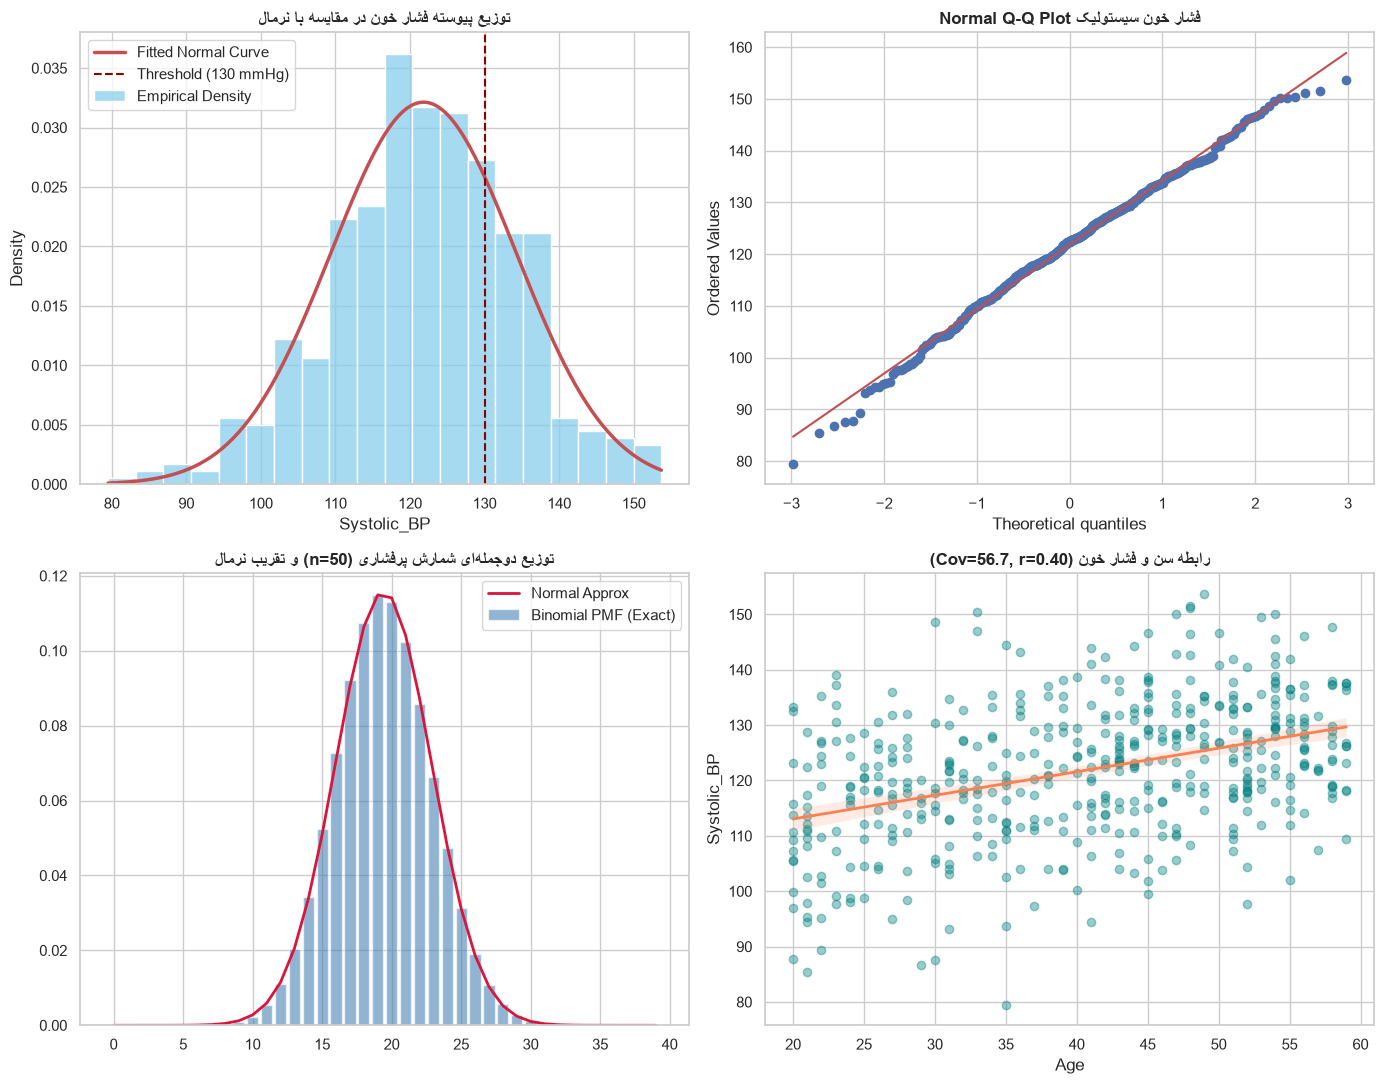

تمامی نمودارهای فاز ۲ با موفقیت رسم و در پوشه figures ذخیره شدند.


In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))


sns.histplot(
    df_clean['Systolic_BP'],
    stat='density',
    color='skyblue',
    bins=20,
    ax=axes[0, 0],
    label='Empirical Density',
)
x_axis = np.linspace(
    df_clean['Systolic_BP'].min(), df_clean['Systolic_BP'].max(), 200
)
axes[0, 0].plot(
    x_axis,
    stats.norm.pdf(x_axis, mu_sbp, std_sbp),
    'r-',
    lw=2.5,
    label='Fitted Normal Curve',
)
axes[0, 0].axvline(
    130, color='darkred', linestyle='--', label='Threshold (130 mmHg)'
)
axes[0, 0].set_title(
    'توزیع پیوسته فشار خون در مقایسه با نرمال', fontsize=12, fontweight='bold'
)
axes[0, 0].legend()


stats.probplot(df_clean['Systolic_BP'], dist='norm', plot=axes[0, 1])
axes[0, 1].set_title(
    'Normal Q-Q Plot فشار خون سیستولیک', fontsize=12, fontweight='bold'
)


k_values = np.arange(0, 40)
pmf_binom = stats.binom.pmf(k_values, n_trials, p_success)
axes[1, 0].bar(
    k_values,
    pmf_binom,
    alpha=0.6,
    color='steelblue',
    label='Binomial PMF (Exact)',
)
axes[1, 0].plot(
    k_values,
    stats.norm.pdf(k_values, expected_k, std_k),
    'crimson',
    lw=2,
    label='Normal Approx',
)
axes[1, 0].set_title(
    f'توزیع دوجمله‌ای شمارش پرفشاری (n={n_trials}) و تقریب نرمال',
    fontsize=12,
    fontweight='bold',
)
axes[1, 0].legend()


sns.regplot(
    data=df_clean,
    x='Age',
    y='Systolic_BP',
    ax=axes[1, 1],
    scatter_kws={'alpha': 0.4, 'color': 'teal'},
    line_kws={'color': 'coral', 'lw': 2},
)
axes[1, 1].set_title(
    f'رابطه سن و فشار خون (Cov={cov_age_sbp:.1f}, r={corr_age_sbp:.2f})',
    fontsize=12,
    fontweight='bold',
)

plt.tight_layout()


figures_dir = Path('../figures')
figures_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(figures_dir / 'phase2_probability_plots.png', dpi=300)

plt.show()
print('تمامی نمودارهای فاز ۲ با موفقیت رسم و در پوشه figures ذخیره شدند.')